# Detección de outliers con el criterio de Tukey (IQR)
**Minería de Datos I — ISTEA (Clases 4 y 5)** · Prof. Kevin Kovacs

**Objetivo:** detectar valores atípicos y decidir qué hacer con ellos.
**Datos:** un ejemplo simple de edades y el dataset [Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance) (Kaggle).
**Qué hice:** apliqué el criterio de Tukey primero a una lista de edades y después a cada variable numérica de un dataset de costos médicos, comparando los boxplots antes y después.
**Resultado principal:** en el dataset de costos médicos se eliminaron 147 de 1.338 filas (11%), casi todas por `charges`.
**Qué aprendí:** un outlier no siempre es un error. Un 180 en una lista de edades sí lo es, pero un gasto médico muy alto puede ser un caso real.

*Notebook desarrollado durante la cursada de Minería de Datos I (ISTEA).*

## Parte 1: el criterio de Tukey con un ejemplo simple

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
edades = np.array([1,14,14,11,22,23,24,180])

In [3]:
edades

array([  1,  14,  14,  11,  22,  23,  24, 180])

{'whiskers': [<matplotlib.lines.Line2D at 0x7fd4cf74fc50>,
 'caps': [<matplotlib.lines.Line2D at 0x7fd4cf74fed0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7fd4cf833890>],
 'medians': [<matplotlib.lines.Line2D at 0x7fd4cf790190>],
 'fliers': [<matplotlib.lines.Line2D at 0x7fd4cf7902d0>],
 'means': []}

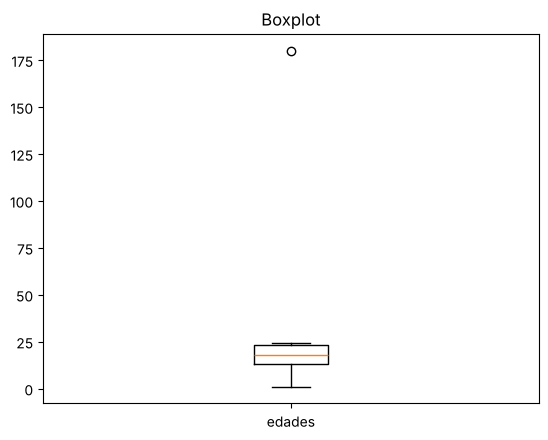

In [4]:
fig, ax = plt.subplots()
ax.set_title('Boxplot')
ax.boxplot(edades, tick_labels = ['edades'])

In [5]:
q1 = np.quantile(edades, 0.25)
q2 = np.quantile(edades, 0.5)
q3 = np.quantile(edades, 0.75)

In [6]:
q1, q2, q3

(np.float64(13.25), np.float64(18.0), np.float64(23.25))

In [7]:
iqr = q3 - q1

In [8]:
sup = q3 + 1.5 * iqr
inf = q1 - 1.5 * iqr
# criterio de Tukey

In [9]:
sup, inf

(np.float64(38.25), np.float64(-1.75))

In [10]:
outliers_indices = np.where((edades > sup) | (edades < inf))

In [11]:
outliers_indices

(array([7]),)

In [12]:
edades = np.delete(edades, outliers_indices)

{'whiskers': [<matplotlib.lines.Line2D at 0x7fd4cf631f90>,
 'caps': [<matplotlib.lines.Line2D at 0x7fd4cf632210>,
 'boxes': [<matplotlib.lines.Line2D at 0x7fd4cf631e50>],
 'medians': [<matplotlib.lines.Line2D at 0x7fd4cf632490>],
 'fliers': [<matplotlib.lines.Line2D at 0x7fd4cf6325d0>],
 'means': []}

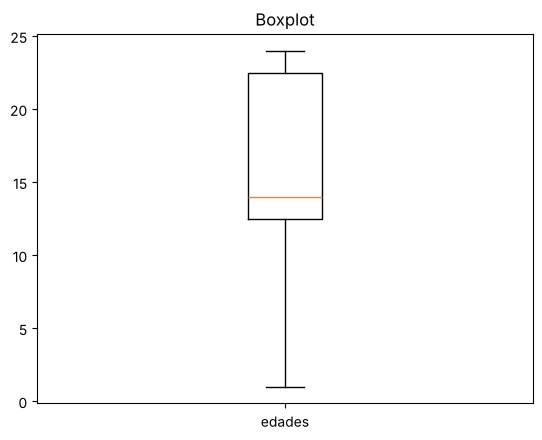

In [13]:
fig, ax = plt.subplots()
ax.set_title('Boxplot')
ax.boxplot(edades, tick_labels = ['edades'])

In [14]:
edades

array([ 1, 14, 14, 11, 22, 23, 24])

## Parte 2: outliers en un dataset real

## Datos
Este notebook usa el archivo **`insurance.csv`**, del dataset [Medical Cost Personal Datasets (Kaggle)](https://www.kaggle.com/datasets/mirichoi0218/insurance).
Para ejecutarlo en Colab, descargá el archivo y subilo a la sesión (ícono de carpeta a la izquierda) antes de correr las celdas.

In [15]:
import pandas as pd

In [16]:
df = pd.read_csv('insurance.csv')

In [17]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


<Axes: >

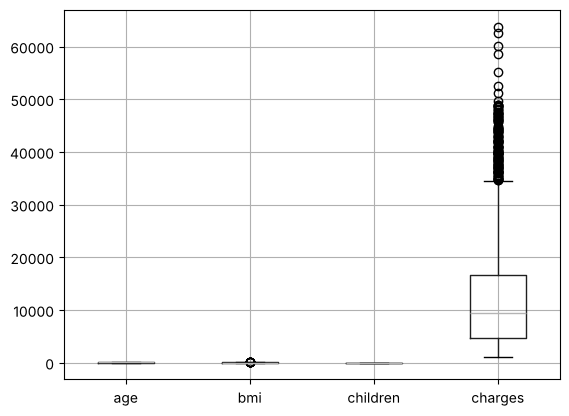

In [19]:
df.select_dtypes('number').boxplot()

<Axes: >

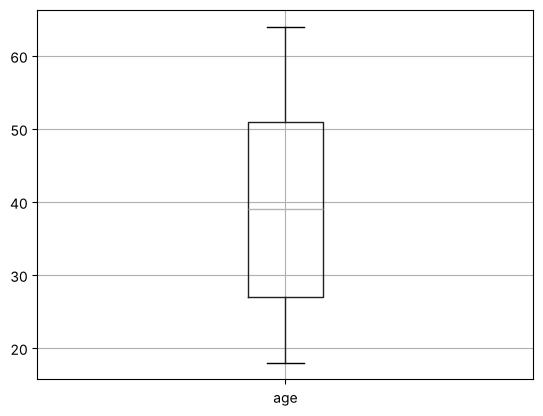

In [20]:
df.boxplot('age')

<Axes: >

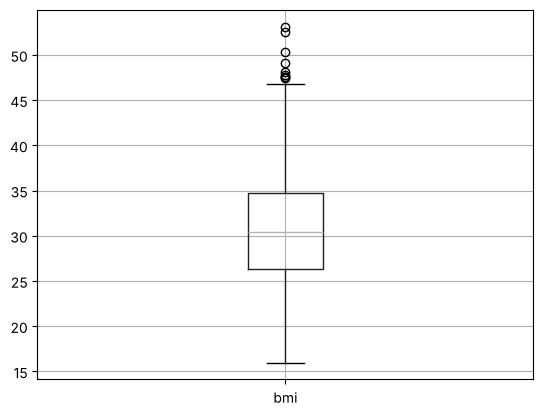

In [21]:
df.boxplot('bmi')

<Axes: >

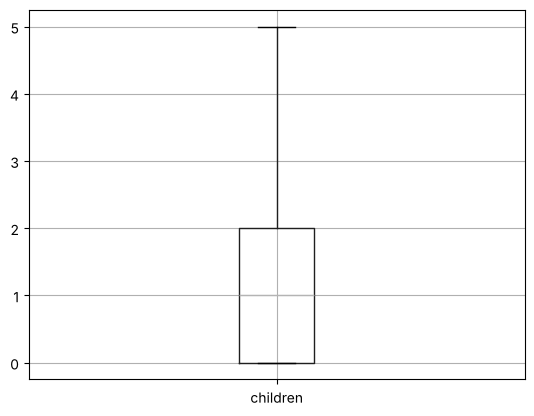

In [22]:
df.boxplot('children')

<Axes: >

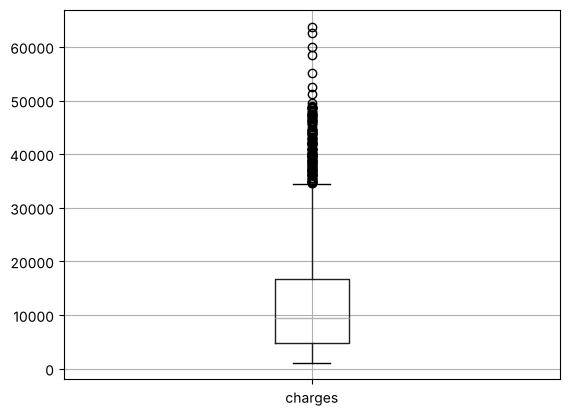

In [23]:
df.boxplot('charges')

In [24]:
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

In [25]:
numeric_columns

Index(['age', 'bmi', 'children', 'charges'], dtype='str')

In [26]:
df[numeric_columns]

,age,bmi,children,charges
0,19,27.900,0,16884.92400
1,18,33.770,1,1725.55230
2,28,33.000,3,4449.46200
3,33,22.705,0,21984.47061
4,32,28.880,0,3866.85520
...,...,...,...,...
1333,50,30.970,3,10600.54830
1334,18,31.920,0,2205.98080
1335,18,36.850,0,1629.83350
1336,21,25.800,0,2007.94500


In [27]:
for col in numeric_columns:
  q1 = df[col].quantile(0.25)
  q3 = df[col].quantile(0.75)
  iqr = q3 - q1
  sup = q3 + 1.5 * iqr
  inf = q1 - 1.5 * iqr
  outliers_indices = df[(df[col] > sup) | (df[col] < inf)].index
  df = df.drop(outliers_indices)

<Axes: >

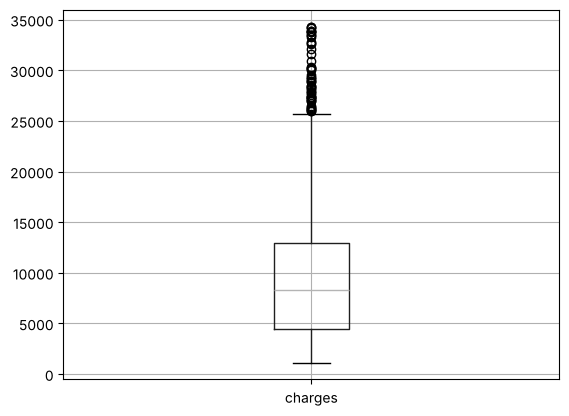

In [28]:
df.boxplot('charges')

<Axes: >

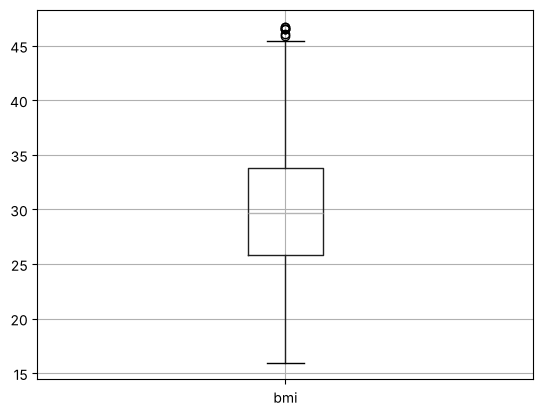

In [29]:
df.boxplot('bmi')

In [30]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

## Conclusiones
- El criterio de Tukey marca como atípico todo valor menor que Q1 − 1,5·IQR o mayor que Q3 + 1,5·IQR. Es simple y no necesita que los datos tengan distribución normal.
- En el ejemplo de edades, el 180 es claramente un error de carga: corresponde eliminarlo.
- En el dataset de costos médicos se eliminaron 147 filas (11% del total): 139 por `charges` y 9 por `bmi`. Esos gastos altos probablemente son reales (por ejemplo, personas fumadoras o con enfermedades), así que eliminarlos puede sesgar un análisis posterior.
- Antes de borrar un outlier hay que preguntarse si es un error o un caso extremo real. La decisión depende del problema, no solo de la fórmula.